<a href="https://colab.research.google.com/github/Leo-Vedo/Github-Actions/blob/master/Regresion_lineal_Avance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mean Squared Error: 23.248766588129108
R² Score: 0.2634309396999791


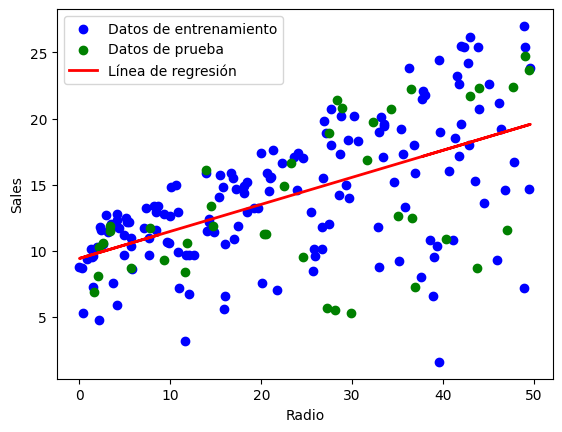

In [5]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Dataset en formato de texto (puedes reemplazar esto con pd.read_csv('Advertising.csv', sep='\t') si tienes el archivo guardado)
csv_data = """TV	Radio	Newspaper	Sales
230.1	37.8	69.2	22.1
44.5	39.3	45.1	10.4
17.2	45.9	69.3	9.3
151.5	41.3	58.5	18.5
180.8	10.8	58.4	12.9
8.7	48.9	75	7.2
57.5	32.8	23.5	11.8
120.2	19.6	11.6	13.2
8.6	2.1	1	4.8
199.8	2.6	21.2	10.6
66.1	5.8	24.2	8.6
214.7	24	4	17.4
23.8	35.1	65.9	9.2
97.5	7.6	7.2	9.7
204.1	32.9	46	19
195.4	47.7	52.9	22.4
67.8	36.6	114	12.5
281.4	39.6	55.8	24.4
69.2	20.5	18.3	11.3
147.3	23.9	19.1	14.6
218.4	27.7	53.4	18
237.4	5.1	23.5	12.5
13.2	15.9	49.6	5.6
228.3	16.9	26.2	15.5
62.3	12.6	18.3	9.7
262.9	3.5	19.5	12
142.9	29.3	12.6	15
240.1	16.7	22.9	15.9
248.8	27.1	22.9	18.9
70.6	16	40.8	10.5
292.9	28.3	43.2	21.4
112.9	17.4	38.6	11.9
97.2	1.5	30	9.6
265.6	20	0.3	17.4
95.7	1.4	7.4	9.5
290.7	4.1	8.5	12.8
266.9	43.8	5	25.4
74.7	49.4	45.7	14.7
43.1	26.7	35.1	10.1
228	37.7	32	21.5
202.5	22.3	31.6	16.6
177	33.4	38.7	17.1
293.6	27.7	1.8	20.7
206.9	8.4	26.4	12.9
25.1	25.7	43.3	8.5
175.1	22.5	31.5	14.9
89.7	9.9	35.7	10.6
239.9	41.5	18.5	23.2
227.2	15.8	49.9	14.8
66.9	11.7	36.8	9.7
199.8	3.1	34.6	11.4
100.4	9.6	3.6	10.7
216.4	41.7	39.6	22.6
182.6	46.2	58.7	21.2
262.7	28.8	15.9	20.2
198.9	49.4	60	23.7
7.3	28.1	41.4	5.5
136.2	19.2	16.6	13.2
210.8	49.6	37.7	23.8
210.7	29.5	9.3	18.4
53.5	2	21.4	8.1
261.3	42.7	54.7	24.2
239.3	15.5	27.3	15.7
102.7	29.6	8.4	14
131.1	42.8	28.9	18
69	9.3	0.9	9.3
31.5	24.6	2.2	9.5
139.3	14.5	10.2	13.4
237.4	27.5	11	18.9
216.8	43.9	27.2	22.3
199.1	30.6	38.7	18.3
109.8	14.3	31.7	12.4
26.8	33	19.3	8.8
129.4	5.7	31.3	11
213.4	24.6	13.1	17
16.9	43.7	89.4	8.7
27.5	1.6	20.7	6.9
120.5	28.5	14.2	14.2
5.4	29.9	9.4	5.3
116	7.7	23.1	11
76.4	26.7	22.3	11.8
239.8	4.1	36.9	12.3
75.3	20.3	32.5	11.3
68.4	44.5	35.6	13.6
213.5	43	33.8	21.7
193.2	18.4	65.7	15.2
76.3	27.5	16	12
110.7	40.6	63.2	16
88.3	25.5	73.4	12.9
109.8	47.8	51.4	16.7
134.3	4.9	9.3	11.2
28.6	1.5	33	7.3
217.7	33.5	59	19.4
250.9	36.5	72.3	22.2
107.4	14	10.9	11.5
163.3	31.6	52.9	16.9
197.6	3.5	5.9	11.7
184.9	21	22	15.5
289.7	42.3	51.2	25.4
135.2	41.7	45.9	17.2
222.4	4.3	49.8	11.7
296.4	36.3	100.9	23.8
280.2	10.1	21.4	14.8
187.9	17.2	17.9	14.7
238.2	34.3	5.3	20.7
137.9	46.4	59	19.2
25	11	29.7	7.2
90.4	0.3	23.2	8.7
13.1	0.4	25.6	5.3
255.4	26.9	5.5	19.8
225.8	8.2	56.5	13.4
241.7	38	23.2	21.8
175.7	15.4	2.4	14.1
209.6	20.6	10.7	15.9
78.2	46.8	34.5	14.6
75.1	35	52.7	12.6
139.2	14.3	25.6	12.2
76.4	0.8	14.8	9.4
125.7	36.9	79.2	15.9
19.4	16	22.3	6.6
141.3	26.8	46.2	15.5
18.8	21.7	50.4	7
224	2.4	15.6	11.6
123.1	34.6	12.4	15.2
229.5	32.3	74.2	19.7
87.2	11.8	25.9	10.6
7.8	38.9	50.6	6.6
80.2	0	9.2	8.8
220.3	49	3.2	24.7
59.6	12	43.1	9.7
0.7	39.6	8.7	1.6
265.2	2.9	43	12.7
8.4	27.2	2.1	5.7
219.8	33.5	45.1	19.6
36.9	38.6	65.6	10.8
48.3	47	8.5	11.6
25.6	39	9.3	9.5
273.7	28.9	59.7	20.8
43	25.9	20.5	9.6
184.9	43.9	1.7	20.7
73.4	17	12.9	10.9
193.7	35.4	75.6	19.2
220.5	33.2	37.9	20.1
104.6	5.7	34.4	10.4
96.2	14.8	38.9	11.4
140.3	1.9	9	10.3
240.1	7.3	8.7	13.2
243.2	49	44.3	25.4
38	40.3	11.9	10.9
44.7	25.8	20.6	10.1
280.7	13.9	37	16.1
121	8.4	48.7	11.6
197.6	23.3	14.2	16.6
171.3	39.7	37.7	19
187.8	21.1	9.5	15.6
4.1	11.6	5.7	3.2
93.9	43.5	50.5	15.3
149.8	1.3	24.3	10.1
11.7	36.9	45.2	7.3
131.7	18.4	34.6	12.9
172.5	18.1	30.7	14.4
85.7	35.8	49.3	13.3
188.4	18.1	25.6	14.9
163.5	36.8	7.4	18
117.2	14.7	5.4	11.9
234.5	3.4	84.8	11.9
17.9	37.6	21.6	8
206.8	5.2	19.4	12.2
215.4	23.6	57.6	17.1
284.3	10.6	6.4	15
50	11.6	18.4	8.4
164.5	20.9	47.4	14.5
19.6	20.1	17	7.6
168.4	7.1	12.8	11.7
222.4	3.4	13.1	11.5
276.9	48.9	41.8	27
248.4	30.2	20.3	20.2
170.2	7.8	35.2	11.7
276.7	2.3	23.7	11.8
165.6	10	17.6	12.6
156.6	2.6	8.3	10.5
218.5	5.4	27.4	12.2
56.2	5.7	29.7	8.7
287.6	43	71.8	26.2
253.8	21.3	30	17.6
205	45.1	19.6	22.6
139.5	2.1	26.6	10.3
191.1	28.7	18.2	17.3
286	13.9	3.7	15.9
18.7	12.1	23.4	6.7
39.5	41.1	5.8	10.8
75.5	10.8	6	9.9
17.2	4.1	31.6	5.9
166.8	42	3.6	19.6
149.7	35.6	6	17.3
38.2	3.7	13.8	7.6
94.2	4.9	8.1	9.7
177	9.3	6.4	12.8
283.6	42	66.2	25.5
232.1	8.6	8.7	13.4
"""

# Leer los datos como un DataFrame utilizando separador de tabulaciones
df = pd.read_csv(io.StringIO(csv_data), sep='\t')

# Seleccionar la nueva variable independiente (TV) y la variable dependiente (Sales)
X = df[['Radio']].values   # Variable predictora
Y = df['Sales'].values  # Variable objetivo

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, Y_train)

Y_pred = model.predict(X_test)

mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("Mean Squared Error:", mse)
print("R² Score:", r2)

# Visualizar los datos de entrenamiento
plt.scatter(X_train, Y_train, color='blue', label='Datos de entrenamiento')

# Visualizar los datos de prueba
plt.scatter(X_test, Y_test, color='green', label='Datos de prueba')

# Visualizar la línea de regresión
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Línea de regresión')

plt.xlabel('Radio')
plt.ylabel('Sales')
plt.legend()
plt.show()